In [18]:
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
import numpy as np
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.metrics import precision_recall_curve, average_precision_score


def plots(model, X_test, y_test, experiment_name="Experiment"):
    
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    
    
    
    #CM
    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(5,4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
    plt.title(f"Confusion Matrix – {experiment_name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.savefig(f"{experiment_name}_CM.png", dpi=300, bbox_inches="tight")
    plt.show()
    
    #ROC
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc = roc_auc_score(y_test, y_prob)
    
    plt.figure(figsize=(6,4))
    plt.plot(fpr, tpr, label=f"AUC = {auc:.3f}")
    plt.plot([0,1], [0,1], linestyle="--")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(f"ROC Curve – {experiment_name}")
    plt.legend()
    plt.savefig(f"{experiment_name}_ROC.png", dpi=300, bbox_inches="tight")
    plt.show()
    
    #PR
    precision, recall, _ = precision_recall_curve(y_test, y_prob)
    ap = average_precision_score(y_test, y_prob)
    
    plt.figure(figsize=(6,4))
    plt.plot(recall, precision, label=f"AP = {ap:.3f}")
    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.title(f"Precision–Recall Curve – {experiment_name}")
    plt.legend()
    plt.savefig(f"{experiment_name}_PR.png", dpi=300, bbox_inches="tight")
    plt.show()
    

In [2]:
#import files
reddit_train = pd.read_csv("/Users/jamesjohnson/Documents/COEN 498 Project/reddit_tfidf_train_fixed.csv")
reddit_val = pd.read_csv("/Users/jamesjohnson/Documents/COEN 498 Project/reddit_tfidf_val_fixed.csv")
reddit_test = pd.read_csv("/Users/jamesjohnson/Documents/COEN 498 Project/reddit_tfidf_test_fixed.csv")
twitter = pd.read_csv("/Users/jamesjohnson/Documents/COEN 498 Project/twitter_tfidf_fixed.csv")

In [3]:
#Reddit data
X_train = reddit_train.iloc[:, :5000].values
y_train = reddit_train.iloc[:, 5001].values

X_val = reddit_val.iloc[:, :5000].values
y_val = reddit_val.iloc[:, 5001].values

X_test_reddit = reddit_test.iloc[:, :5000].values
y_test_reddit = reddit_test.iloc[:, 5001].values

#Twitter data
X_twitter = twitter.iloc[:, :5000].values
y_twitter = twitter.iloc[:, 5000].values


Reddit Validation Accuracy: 0.9414443372977607
Reddit Test Accuracy: 0.9388793657595886
              precision    recall  f1-score   support

           0       0.94      0.97      0.95     11202
           1       0.94      0.90      0.92      7466

    accuracy                           0.94     18668
   macro avg       0.94      0.93      0.94     18668
weighted avg       0.94      0.94      0.94     18668



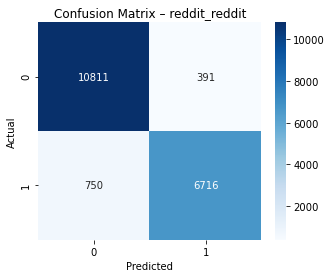

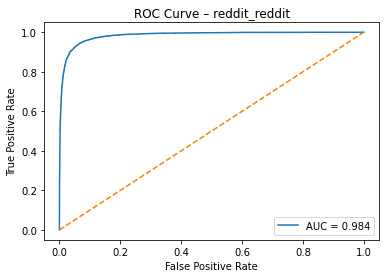

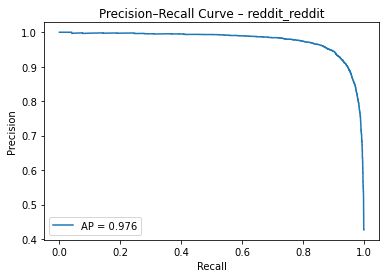

In [19]:
#Train with reddit and test with reddit
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

val_preds = model.predict(X_val)
print("Reddit Validation Accuracy:", accuracy_score(y_val, val_preds))

reddit_test_preds = model.predict(X_test_reddit)
print("Reddit Test Accuracy:", accuracy_score(y_test_reddit, reddit_test_preds))
print(classification_report(y_test_reddit, reddit_test_preds))

plots(model, X_test_reddit, y_test_reddit, "reddit_reddit")

Twitter Test Accuracy: 0.69675
              precision    recall  f1-score   support

           0       0.67      0.75      0.71      1981
           1       0.73      0.64      0.68      2019

    accuracy                           0.70      4000
   macro avg       0.70      0.70      0.70      4000
weighted avg       0.70      0.70      0.70      4000



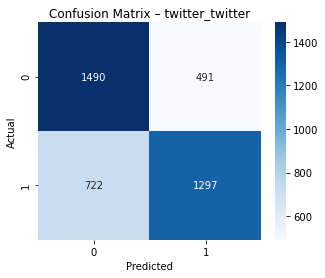

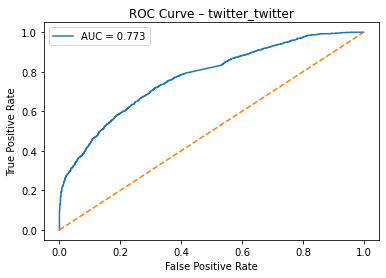

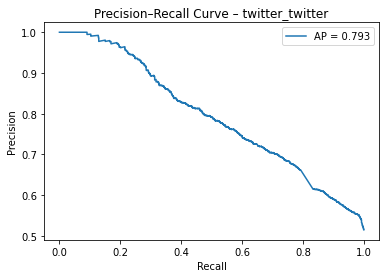

In [20]:
#Train with twitter test with twitter
#split data set 80% 20%
X_twitter_train, X_twitter_test, y_twitter_train, y_twitter_test = train_test_split(
    X_twitter, y_twitter, test_size=0.2, random_state=42
)

model_twitter = LogisticRegression(max_iter=1000)
model_twitter.fit(X_twitter_train, y_twitter_train)

twitter_preds = model_twitter.predict(X_twitter_test)
print("Twitter Test Accuracy:", accuracy_score(y_twitter_test, twitter_preds))
print(classification_report(y_twitter_test, twitter_preds))
plots(model_twitter, X_twitter_test, y_twitter_test, "twitter_twitter")

Reddit to Twitter Accuracy: 0.55075
              precision    recall  f1-score   support

           0       0.53      0.93      0.67     10000
           1       0.71      0.17      0.28     10000

    accuracy                           0.55     20000
   macro avg       0.62      0.55      0.48     20000
weighted avg       0.62      0.55      0.48     20000



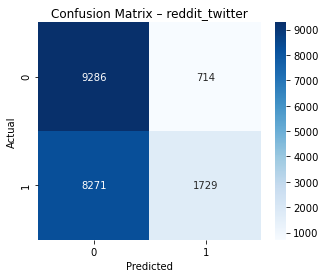

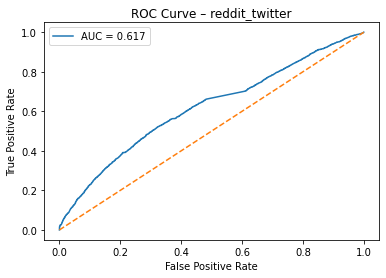

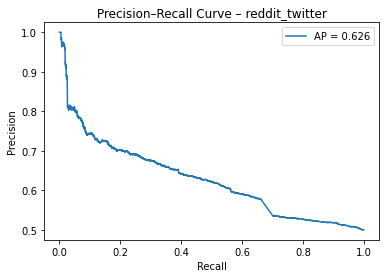

In [21]:
#Train with reddit and test with twitter
model_reddit_to_twitter = LogisticRegression(max_iter=1000)
model_reddit_to_twitter.fit(X_train, y_train)

twitter_preds_cross = model_reddit_to_twitter.predict(X_twitter)
print("Reddit to Twitter Accuracy:", accuracy_score(y_twitter, twitter_preds_cross))
print(classification_report(y_twitter, twitter_preds_cross))

plots(model_reddit_to_twitter, X_twitter, y_twitter, "reddit_twitter")

Reddit and 20% Twitter to Twitter Accuracy: 0.5998125
              precision    recall  f1-score   support

           0       0.56      0.90      0.69      7956
           1       0.75      0.30      0.43      8044

    accuracy                           0.60     16000
   macro avg       0.66      0.60      0.56     16000
weighted avg       0.66      0.60      0.56     16000



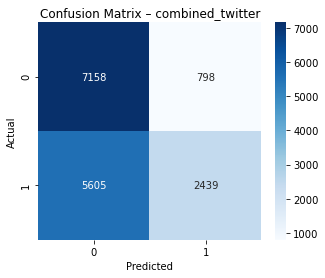

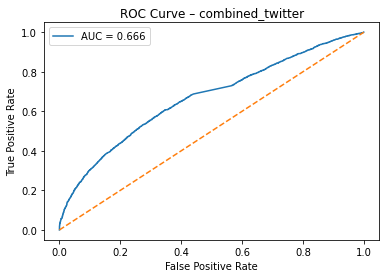

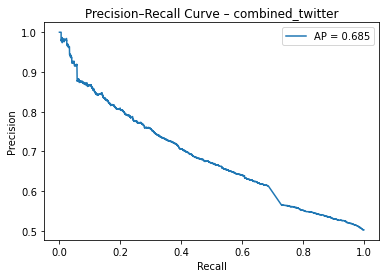

Reddit and 20% Twitter to Reddit Test Accuracy: 0.9386650953503322
              precision    recall  f1-score   support

           0       0.94      0.96      0.95     11202
           1       0.94      0.91      0.92      7466

    accuracy                           0.94     18668
   macro avg       0.94      0.93      0.94     18668
weighted avg       0.94      0.94      0.94     18668



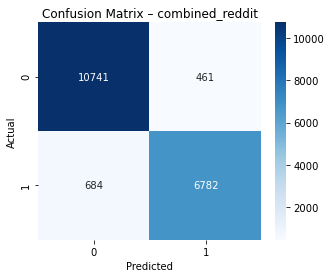

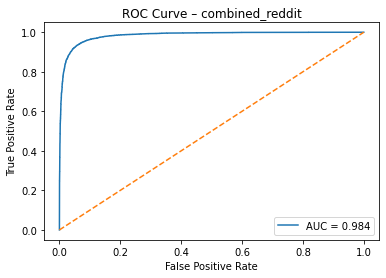

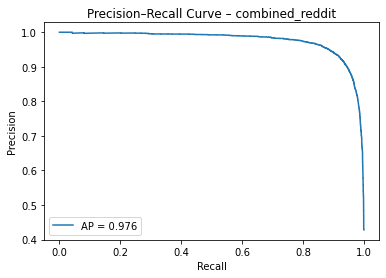

In [22]:
#Train with reddit and %20 twitter and Test with 80% twitter
#split
X_twitter_add, X_twitter_test2, y_twitter_add, y_twitter_test2 = train_test_split(
    X_twitter, y_twitter, test_size=0.8, random_state=42
)

# Combine reddit training and 20% Twitter 
X_combined_train = np.vstack((X_train, X_twitter_add))
y_combined_train = np.hstack((y_train, y_twitter_add))

#train
model_combined = LogisticRegression(max_iter=1000)
model_combined.fit(X_combined_train, y_combined_train)

#test on remaing twitter data
twitter_preds_combined = model_combined.predict(X_twitter_test2)
print("Reddit and 20% Twitter to Twitter Accuracy:", accuracy_score(y_twitter_test2, twitter_preds_combined))
print(classification_report(y_twitter_test2, twitter_preds_combined))

plots(model_combined, X_twitter_test2, y_twitter_test2, "combined_twitter")


#test on reddit
reddit_preds_combined = model_combined.predict(X_test_reddit)
print("Reddit and 20% Twitter to Reddit Test Accuracy:",accuracy_score(y_test_reddit, reddit_preds_combined))
print(classification_report(y_test_reddit, reddit_preds_combined))

plots(model_combined, X_test_reddit, y_test_reddit, "combined_reddit")
